# SMS Spam Detection

Classifies 5,572 SMS messages as **spam** or **ham** (not spam) with a Bag-of-Words representation, compares Multinomial Naive Bayes and Logistic Regression, and analyzes the errors of the best model.

**Data:** `spam.csv` (see [`../data/README.md`](../data/README.md)).

In [49]:
# Step 1: Import the libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../data/"

In [50]:
# Step 2: Load the dataset (`spam.csv`)
spam_data = pd.read_csv(DATA_DIR + 'spam.csv', encoding='latin-1')
spam_data = spam_data.rename(columns={"v1": "Label", "v2": "Message"})
spam_data = spam_data[["Label", "Message"]]

In [51]:
spam_data

,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [52]:
# Convert the labels to binary (ham = 0, spam = 1)
spam_data["Label"] = spam_data["Label"].map({"ham": 0, "spam": 1})
print("Primeras filas del conjunto de datos:")
spam_data.head()

Primeras filas del conjunto de datos:


,Label,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [53]:
# Step 3: Split into training and test sets (80/20)
X = spam_data["Message"]
y = spam_data["Label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [54]:
# Step 4: Vectorize the text (Bag-of-Words)
vectorizer = CountVectorizer(stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [55]:
# Step 5: Compare models
# Model 1: Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)
nb_predictions = nb_model.predict(X_test_vec)
nb_report = classification_report(y_test, nb_predictions, output_dict=True)

In [56]:
# Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=200)
lr_model.fit(X_train_vec, y_train)
lr_predictions = lr_model.predict(X_test_vec)
lr_report = classification_report(y_test, lr_predictions, output_dict=True)

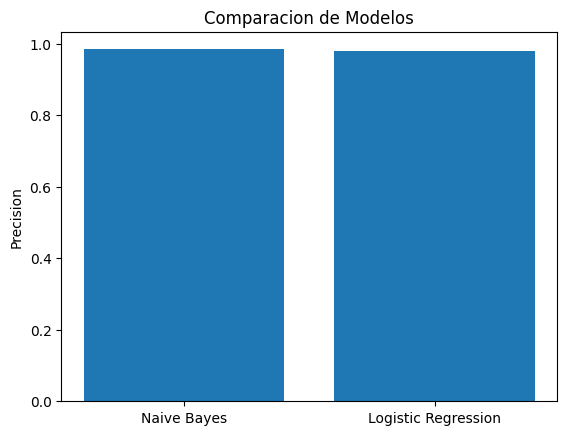

In [57]:
# Step 6: Visualize the results
# Accuracy of each model
model_scores = {
    "Naive Bayes": nb_report["accuracy"],
    "Logistic Regression": lr_report["accuracy"]
}

plt.bar(model_scores.keys(), model_scores.values())
plt.title("Comparacion de Modelos")
plt.ylabel("Precision")
plt.show()

Mejor modelo: Naive Bayes


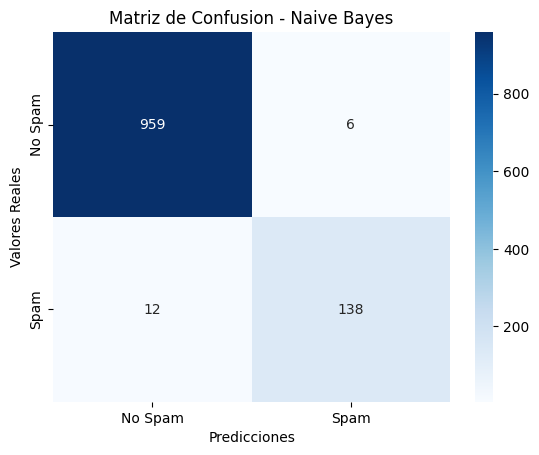

In [58]:
# Confusion matrix of the best model
best_model = "Naive Bayes" if nb_report["accuracy"] > lr_report["accuracy"] else "Logistic Regression"
print(f"Mejor modelo: {best_model}")

if best_model == "Naive Bayes":
    cm = confusion_matrix(y_test, nb_predictions)
else:
    cm = confusion_matrix(y_test, lr_predictions)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Spam", "Spam"], yticklabels=["No Spam", "Spam"])
plt.xlabel("Predicciones")
plt.ylabel("Valores Reales")
plt.title(f"Matriz de Confusion - {best_model}")
plt.show()

In [59]:
# Step 7: Classification report of the best model
if best_model == "Naive Bayes":
    print("Reporte del Mejor Modelo (Naive Bayes):")
    print(classification_report(y_test, nb_predictions))
    print("\nMatriz de Confusión:")
    print(confusion_matrix(y_test, nb_predictions))
else:
    print("Reporte del Mejor Modelo (Logistic Regression):")
    print(classification_report(y_test, lr_predictions))
    print("\nMatriz de Confusión:")
    print(confusion_matrix(y_test, lr_predictions))

Reporte del Mejor Modelo (Naive Bayes):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       965
           1       0.96      0.92      0.94       150

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Matriz de Confusión:
[[959   6]
 [ 12 138]]


## Results

**Selected model: Multinomial Naive Bayes**, which scored higher than Logistic Regression on the test set.

| Class | Precision | Recall | F1-score |
|---|---|---|---|
| Ham (0) | 0.99 | 0.99 | 0.99 |
| Spam (1) | 0.96 | 0.92 | 0.94 |

**Accuracy: 98%** on 1,115 test messages.

**Confusion matrix**

- True negatives: 959 ham messages correctly identified.
- False positives: only 6 ham messages flagged as spam.
- True positives: 138 spam messages detected.
- False negatives: 12 spam messages were missed, which would matter in critical uses such as filtering malicious messages.

**Strengths:** high precision on both classes, few false positives and false negatives, and a simple model that trains in seconds.